<a href="https://colab.research.google.com/github/ML-HW-SYS/a2-AaronGoldblatt/blob/main/5_quantization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **5. Quantization**


## 5.0 Setup Capabilities

In [2]:
# Mount google drive
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [3]:
# Make sure your token is stored in a txt file at the location below.
# This way there is no risk that you will push it to your repo
# Never share your token with anyone, it is basically your github password!
with open('/content/gdrive/MyDrive/ece5545/token.txt') as f:
    token = f.readline().strip()
# Use another file to store your github username
with open('/content/gdrive/MyDrive/ece5545/git_username.txt') as f:
    handle = f.readline().strip()

In [4]:
# Clone your github repo
YOUR_TOKEN = token
YOUR_HANDLE = handle
BRANCH = "main"

%mkdir /content/gdrive/MyDrive/ece5545
%cd /content/gdrive/MyDrive/ece5545
!git clone https://{YOUR_TOKEN}@github.com/ML-HW-SYS/a2-{YOUR_HANDLE}.git
%cd /content/gdrive/MyDrive/ece5545/a2-{YOUR_HANDLE}
!git checkout {BRANCH}
!git pull
%cd /content/gdrive/MyDrive/ece5545

PROJECT_ROOT = f"/content/gdrive/MyDrive/ece5545/a2-{YOUR_HANDLE}"

mkdir: cannot create directory ‘/content/gdrive/MyDrive/ece5545’: File exists
/content/gdrive/MyDrive/ece5545
fatal: destination path 'a2-AaronGoldblatt' already exists and is not an empty directory.
/content/gdrive/MyDrive/ece5545/a2-AaronGoldblatt
Already on 'main'
Your branch is up to date with 'origin/main'.
Already up to date.
/content/gdrive/MyDrive/ece5545


In [5]:
# This extension reloads all imports before running each cell
%load_ext autoreload
%autoreload 2

Please verify the cell below prints out the github repository.

In [6]:
!ls '{PROJECT_ROOT}'

1_audio_preprocessing.ipynb	     4_model_conversion_wow.ipynb     model_training_output.txt
2_size_estimator_and_profiler.ipynb  5_quantization.ipynb	      README.md
3_training_and_analysis.ipynb	     6_pruning.ipynb		      requirements.txt
3_training_and_analysis_wow.ipynb    arduino_nano_33_ble_tutorial.md  src
4_model_conversion.ipynb	     images			      tests


### Install required packages

In [7]:
# Install libraries
!pip install tqdm
!pip install torchaudio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 102.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 84.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 57.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 12.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 81.5 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstalling nvidia-nvjitlink-cu12-12.5.82:
      Successfully uninstalled nvidia-nvjitli

### Import code dependencies

In [8]:
# Import libraries
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
import numpy as np
import copy
import os

import sys

# Adding assignment 2 to the system path
# -- make sure this matches your git directory
sys.path.insert(0, PROJECT_ROOT)

# Import data_proc to use data processing functions
import src.data_proc as data_proc

# Import constants to use constants defined for training
from src.constants import *

# Set random seed
# Make sure the shuffling and picking is deterministic
# Note that different value of random_seed may change rate of variation in loss/accuracy during training
# Using the same random seed value every time you rerun the notebook will
# reproduce the training and testing results
random_seed = RANDOM_SEED
torch.manual_seed(random_seed)
torch.cuda.manual_seed(random_seed)
np.random.seed(random_seed)

Model folders are created, 
PyTorch models will be saved in /content/gdrive/MyDrive/ece5545/models/torch_models, 
ONNX models will be saved in /content/gdrive/MyDrive/ece5545/models/onnx_models, 
TensorFlow Saved Models will be saved in /content/gdrive/MyDrive/ece5545/models/tf_models, 
TensorFlow Lite models will be saved in /content/gdrive/MyDrive/ece5545/models/tflite_models, 
TensorFlow Lite Micro models will be saved in /content/gdrive/MyDrive/ece5545/models/micro_models.


## 5.1 Define Quantization Functions

There are some test cases in the `tests` folder to verify basic functionality of your implemented functions--these will be run automatically every time you check in your code. Additionally, we've left some simple tests in this notebook as well for you to try things out.



#### TODO 0: Implement the backward pass of `ste_round` function in `src/quant.py`

In [ ]:
# add a test if you like. There's already one under tests/


#### TODO 1: Implement the `linear_quantize` function in `src/quant.py`


In [9]:
from src.quant import linear_quantize

# Mini test case for linear_quantize
with torch.no_grad():
    x = torch.tensor([2, -0.5, 0., 1.])
    scale = 1
    zero = 0
    y = linear_quantize(x, scale, zero)
    print(y)

tensor([2., 0., 0., 1.])


#### TODO 2: Implement the `SymmetricQuantFunction` forward function in `src/quant.py`


In [10]:
from src.quant import SymmetricQuantFunction

quant_f = SymmetricQuantFunction.apply

x = torch.tensor([2, -0.5, 0., 1.])
x.requires_grad = True
bw = 2
y = quant_f(x, bw, scale, zero)
(y ** 2).sum().backward()

print(y)
print(x.grad)

tensor([1., -0., 0., 1.], grad_fn=<SymmetricQuantFunctionBackward>)
tensor([2., -0., 0., 2.])


#### TODO 3: Implement the `AsymmetricQuantFunction` forward function in `src/quant.py`

In [11]:
from src.quant import AsymmetricQuantFunction

quant_f = AsymmetricQuantFunction.apply

x = torch.tensor([2, -0.5, 0., 1.])
x.requires_grad = True
bw = 2
y = quant_f(x, bw, scale, zero)
(y ** 2).sum().backward()

print(y)
print(x.grad)

tensor([2., -0., 0., 1.], grad_fn=<AsymmetricQuantFunctionBackward>)
tensor([4., -0., 0., 2.])


#### TODO 4: Finish the Implement of `get_quantization_params` function in `src/quant.py`

In [12]:
from src.quant import QConfig

qconfig = QConfig(quant_bits=4, is_symmetric=True)
print(qconfig.get_quantization_params(x.min(), x.max()))

qconfig = QConfig(quant_bits=4, is_symmetric=False)
print(qconfig.get_quantization_params(x.min(), x.max()))

(tensor(0.2857), tensor(0))
(tensor(0.1667), tensor(3.))


#### TODO 5: Implement the `quantize_weights_bias` function in `src/quant.py`

In [13]:
from src.quant import quantize_weights_bias, QConfig

qconfig = QConfig(quant_bits=4, is_symmetric=True)

w1 = nn.Parameter(torch.tensor([2, -0.5, 0., 1.]))
qw1 = quantize_weights_bias(w1, qconfig)
print(qw1.data)

w2 = nn.Parameter(torch.tensor([2.5, -1, 0., 1.5]))
qw2 = quantize_weights_bias(w2, qconfig)
print(qw2.data)

tensor([ 7., -2.,  0.,  3.])
tensor([ 7., -3.,  0.,  4.])


## 5.2 Quantization Function for Linear and Convolution Layer

#### TODO 6: Finish the implementation of `conv2d_linear_quantized` function in `src/quant.py`

In [14]:
import torch.nn as nn
from src.quant import QuantWrapper

layer = nn.Linear(2, 2)
layer.weight.data = torch.tensor([[0.1, 0.1], [-0.1, 0.1]]).view(2, 2).float()
layer.bias.data = torch.tensor([1, 2]).view(*layer.bias.shape).float()
x = torch.tensor([[0., 1]])
print(layer(x))

quant_layer = QuantWrapper(
    layer,
    QConfig(quant_bits=4, is_symmetric=True),
    QConfig(quant_bits=4, is_symmetric=True),
    QConfig(quant_bits=4, is_symmetric=True))
print(quant_layer(x))


tensor([[1.1000, 2.1000]], grad_fn=<AddmmBackward0>)
tensor([[0.9571, 2.1000]], grad_fn=<AddmmBackward0>)


## 5.3 Prepare model for QAT (Quantization Aware Training)

### Get Audio Processor, Devices, Data Loader, and Model

NOTE: This is identical to section 2.2 .

In [20]:
# Create audio_processor
# DATASET_DIR is defined in constants.py
# HINT: In case loading data takes too long, move the dataset from gdrive to /content/ and change the path accordingly.
audio_processor = data_proc.AudioProcessor(data_dir=DATASET_DIR)
print("Audio_processor created")

# Define device
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("cpu")
print(f'Using {device} to run the training scrpit.')

# Define data loaders
from src.loaders import make_data_loaders
data_loaders = make_data_loaders(audio_processor, device)
train_loader = data_loaders['training']
test_loader = data_loaders['testing']
valid_loader = data_loaders['validation']

# Create a full precision (float32) TinyConv model
from src.networks import TinyConv
model_fp32 = TinyConv(model_settings=audio_processor.model_settings, \
    n_input=1, n_output=audio_processor.num_labels)

model_fp32

Audio_processor created
Using cpu to run the training scrpit.
Train size: 10556 Val size: 1333 Test size: 1368


TinyConv(
  (conv_reshape): Reshape(output_shape=(-1, 1, 49, 40))
  (conv): Conv2d(1, 8, kernel_size=(10, 8), stride=(2, 2), padding=(5, 3))
  (relu): ReLU()
  (dropout): Dropout(p=0.5, inplace=False)
  (fc_reshape): Reshape(output_shape=(-1, 4000))
  (fc): Linear(in_features=4000, out_features=4, bias=True)
  (softmax): Softmax(dim=1)
)

### Load Pretrained Model for Quantization Aware Finetuning

In this notebook, we will load the previously trained 32-bits float model to finetune it in a quantizaiton-aware way.



In [21]:
!ls {TORCH_DIR}

 fp32_checkpoint.pt		  '(QAT4bit)quant_0.pt'
 fp32_checkpoint.pt.old		   quant_checkpoint.pt
 fp32_finetune_checkpoint.pt	   quant_checkpoint.pt.old
 fp32_finetune_checkpoint.pt.old   tinyconv_float32_init_seed0_92.25%_0.pt


### **TODO: Replace the torch_path model with the model you created in the last section.**

You can find the name of your file in `TORCH_DIR` under the folder icon to the left. (Or from running the tab above).

In [22]:
# TODO: Replace me!
torch_path = os.path.join(TORCH_DIR, "tinyconv_float32_init_seed0_92.25%_0.pt")

# Load model
model_fp32.load_state_dict(torch.load(torch_path))
model_fp32

<ipython-input-22-8e12b9af4e77>:5: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_fp32.load_state_dict(torch.load(torch_path))


TinyConv(
  (conv_reshape): Reshape(output_shape=(-1, 1, 49, 40))
  (conv): Conv2d(1, 8, kernel_size=(10, 8), stride=(2, 2), padding=(5, 3))
  (relu): ReLU()
  (dropout): Dropout(p=0.5, inplace=False)
  (fc_reshape): Reshape(output_shape=(-1, 4000))
  (fc): Linear(in_features=4000, out_features=4, bias=True)
  (softmax): Softmax(dim=1)
)

### Define settings for weight and activation quantization

In [23]:
# We choose 4 bit quantization as an example because accuracy improvements will
# be more obvious with 4-bit or lower bit quantization
QUANT_BITS = 4
# Settings for activations quantization: n-bit asymmetric quantization
a_qconfig = QConfig(quant_bits=QUANT_BITS, is_symmetric=False)
# Settings for weights quantization: n-bit symmetric quantization
w_qconfig = QConfig(quant_bits=QUANT_BITS, is_symmetric=True)
# Settings for bias quantization: n-bit symmetric quantization
b_qconfig = QConfig(quant_bits=QUANT_BITS, is_symmetric=True)

### Prepare quantization aware training model

In [24]:
from src.quant import quantize_model
qat_model_nbit = quantize_model(
    model_fp32, a_qconfig=a_qconfig, w_qconfig=w_qconfig, b_qconfig=b_qconfig)

# Print to see the model prepared for QAT
print(qat_model_nbit)

TinyConv(
  (conv_reshape): Reshape(output_shape=(-1, 1, 49, 40))
  (conv): QuantWrapper(
    (module): Conv2d(1, 8, kernel_size=(10, 8), stride=(2, 2), padding=(5, 3))
  	(activation): quant_bits=4, quant_mode=asymmetric, prev_scale=None, prev_zeropoint=None, prev_min=None, prev_max=None  
  	(weight): quant_bits=4, quant_mode=symmetric, prev_scale=None, prev_zeropoint=None, prev_min=None, prev_max=None  
  	(bias): quant_bits=4, quant_mode=symmetric, prev_scale=None, prev_zeropoint=None, prev_min=None, prev_max=None  
  )
  (relu): ReLU()
  (dropout): Dropout(p=0.5, inplace=False)
  (fc_reshape): Reshape(output_shape=(-1, 4000))
  (fc): QuantWrapper(
    (module): Linear(in_features=4000, out_features=4, bias=True)
  	(activation): quant_bits=4, quant_mode=asymmetric, prev_scale=None, prev_zeropoint=None, prev_min=None, prev_max=None  
  	(weight): quant_bits=4, quant_mode=symmetric, prev_scale=None, prev_zeropoint=None, prev_min=None, prev_max=None  
  	(bias): quant_bits=4, quant_m

##  5.4 Finetuning

In this training, we will finetune the 32-bits float pretrained model. The goal is to finetune the weights of the 32-bits float model such that the resulted model will have better accuracy after quantization.

### Quantization Aware Finetuning

In [36]:
import time
from src.train_val_test_utils import train, test
from src.train_val_test_utils import create_optimizer


def run_training(model, data_loaders, n_epoch, log_interval, optimizer, scheduler=None,
                 save_interval=1, resume=True, checkpoint_path=None, verbose=False):
    test_loader = data_loaders['testing']
    with tqdm(total=n_epoch) as pbar:
        completed_epoch = 1
        if resume:
            try:
                #continue training with previous model if one exists
                if checkpoint_path is None:
                    raise ValueError
                checkpoint = torch.load(checkpoint_path)
                model.load_state_dict(checkpoint['model_state_dict'])
                optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
                if scheduler is not None:
                    scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
                completed_epoch = checkpoint["epoch"] + 1
                model.eval()
                pbar.update(completed_epoch)
            except:
                pass

        for epoch in range(completed_epoch, n_epoch + 1):
            train_iters = len(data_loaders['training'])
            train(model, data_loaders, optimizer, epoch, device, verbose)
            test(test_loader, model, device,
                 epoch=None, loader_type='Test')

            if scheduler is not None:
                scheduler.step()
            #checkpoint the model every run
            if epoch % save_interval == 0 and checkpoint_path is not None:
                torch.save({
                    'epoch': epoch,
                    'model_state_dict': model.state_dict(),
                    'optimizer_state_dict': optimizer.state_dict(),
                    'scheduler_state_dict': scheduler.state_dict() if scheduler is not None else None
                }, checkpoint_path)

            # Update epoch pbar
            pbar.update(1)


verbose = False
log_interval = 100
num_batches = len(train_loader)
n_epoch = 30
print(f'#batches: {num_batches} \n#epochs: {n_epoch} \n#total training steps: {num_batches * n_epoch}')

# Create optimizer
optimizer_quant = create_optimizer(model=qat_model_nbit, learning_rate=0.001)
print(optimizer_quant.state_dict())

checkpoint_path = os.path.join(TORCH_DIR, "quant_checkpoint.pt")
qat_model_nbit.to(device)
run_training(
    model=qat_model_nbit, data_loaders=data_loaders,
    n_epoch=n_epoch, log_interval=log_interval,
    optimizer=optimizer_quant, scheduler=None,
    resume=False,
    checkpoint_path=checkpoint_path,
    verbose=verbose
)

### Finetune the Float Model

For fair comparison, we conduct the same funetuning for the float model.

In [ ]:
# Create optimizer
optimizer_fp32 = create_optimizer(model=model_fp32, learning_rate=0.0001)

checkpoint_path = os.path.join(TORCH_DIR, "fp32_finetune_checkpoint.pt")
model_fp32.to(device)
run_training(
    model=model_fp32, data_loaders=data_loaders,
    n_epoch=n_epoch, log_interval=log_interval,
    optimizer=optimizer_fp32, scheduler=None,
    resume=False,
    checkpoint_path=checkpoint_path,
    verbose=verbose
)

  0%|          | 0/30 [00:00<?, ?it/s]

Val Acc Epoch 1 = 92.42%, Train loss = 0.312
Val Acc Epoch 2 = 92.65%, Train loss = 0.307
Val Acc Epoch 3 = 92.05%, Train loss = 0.299
Val Acc Epoch 4 = 92.42%, Train loss = 0.3
Val Acc Epoch 5 = 92.35%, Train loss = 0.286
Val Acc Epoch 6 = 92.87%, Train loss = 0.305
Val Acc Epoch 7 = 92.42%, Train loss = 0.301
Val Acc Epoch 8 = 93.02%, Train loss = 0.298
Val Acc Epoch 9 = 93.32%, Train loss = 0.298
Val Acc Epoch 10 = 93.1%, Train loss = 0.299
Val Acc Epoch 11 = 93.1%, Train loss = 0.287
Val Acc Epoch 12 = 92.5%, Train loss = 0.297
Val Acc Epoch 13 = 92.27%, Train loss = 0.295
Val Acc Epoch 14 = 93.02%, Train loss = 0.297
Val Acc Epoch 15 = 92.5%, Train loss = 0.282
Val Acc Epoch 16 = 93.4%, Train loss = 0.29
Val Acc Epoch 17 = 93.32%, Train loss = 0.289
Val Acc Epoch 18 = 94.0%, Train loss = 0.297
Val Acc Epoch 19 = 92.8%, Train loss = 0.287
Val Acc Epoch 20 = 93.1%, Train loss = 0.283
Val Acc Epoch 21 = 93.25%, Train loss = 0.29
Val Acc Epoch 22 = 92.5%, Train loss = 0.28
Val Acc Epo

## 5.5 Testing

We will compute the accuracy of the finetuned model in train/val/test set in this section.
Note that this is not the final accuracy we want the model to perform well on.
We would like our quantized-aware-finetuned model to perform well when quantized into integer.
But the training/validation/testing accuracy of these model in quantization simulation model is still worth looking at for sanity checking purpose.

Train size: 10556 Val size: 1333 Test size: 1368


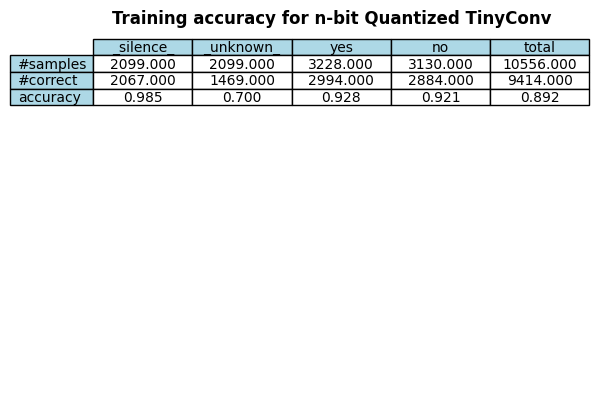

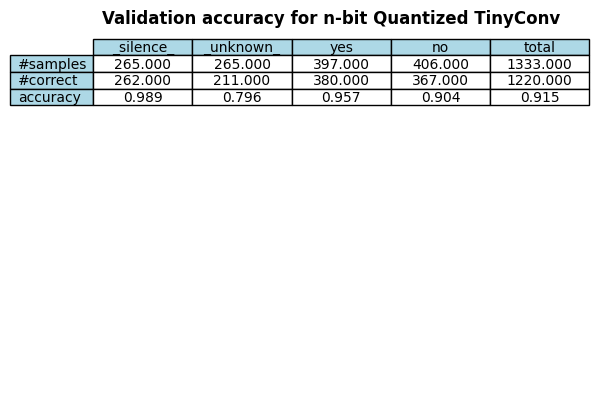

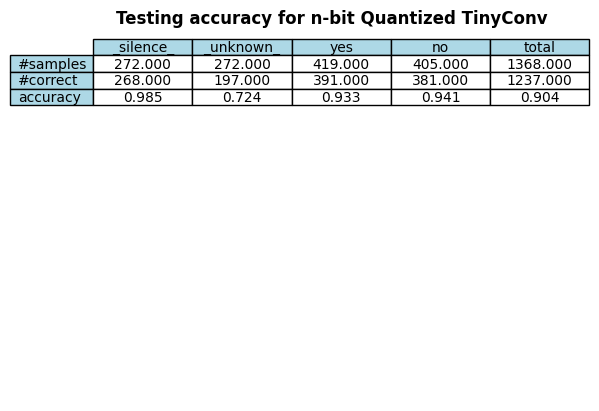

0.9042397660818714

In [ ]:
from src.train_val_test_utils import plot_acc

test_time_data_loaders = make_data_loaders(
    audio_processor, device,
    test_batch_size=1, valid_batch_size=1,
    num_workers=0
)

plot_acc(
    test_time_data_loaders['training'], qat_model_nbit, audio_processor, device,
    "Training", 'n-bit Quantized TinyConv', "float")
plot_acc(
    test_time_data_loaders['validation'], qat_model_nbit, audio_processor, device,
    "Validation", 'n-bit Quantized TinyConv', "float")
plot_acc(
    test_time_data_loaders['testing'], qat_model_nbit, audio_processor, device,
    'Testing', 'n-bit Quantized TinyConv', "float")

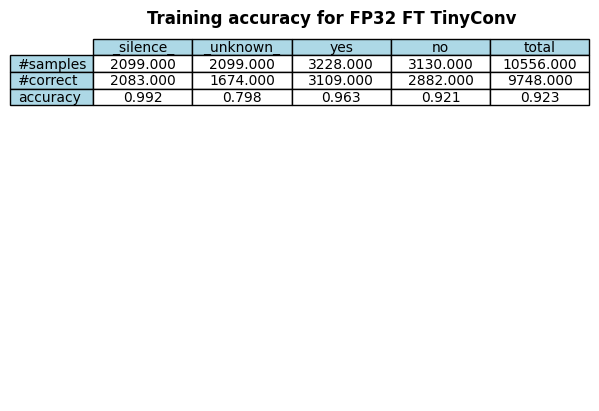

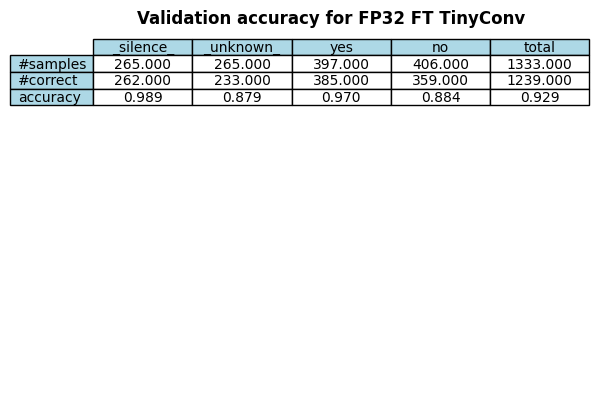

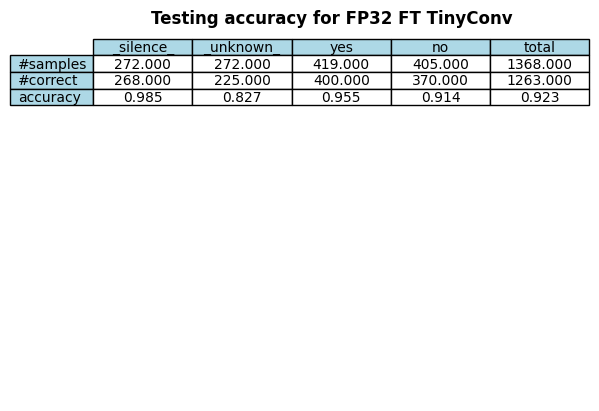

In [ ]:
plot_acc(
    test_time_data_loaders['training'], model_fp32, audio_processor, device,
    "Training", 'FP32 FT TinyConv', "float")
plot_acc(
    test_time_data_loaders['validation'], model_fp32, audio_processor, device,
    "Validation", 'FP32 FT TinyConv', "float")
acc = plot_acc(
    test_time_data_loaders['testing'], model_fp32, audio_processor, device,
    'Testing', 'FP32 FT TinyConv', "float")

## 5.6 Saving the Trained Model

In [ ]:
from src.train_val_test_utils import choose_name
from src.quant import dequantize_model

# Save the qat model
qat_model_nbit_float = dequantize_model(qat_model_nbit)
file_name = choose_name("quant")
# You can also define your own path
qat_torch_path = os.path.join(TORCH_DIR, f'(QAT{QUANT_BITS}bit){file_name}.pt')
# Save the trained n-bit qat pytorch model to PATH
torch.save(qat_model_nbit.state_dict(), qat_torch_path)
qat_torch_path

Layer to be deprepared: QuantWrapper: conv
Layer to be deprepared: QuantWrapper: fc
The model's will be stored as: 
 quant_0


'/content/gdrive/MyDrive/ece5545/models/torch_models/(QAT4bit)quant_0.pt'

## 5.7 Understanding and Evaluate the Effectiveness of Quantization-Aware Training (QAT)

### Model conversion: Quantized/Float Fine-tuning Model Converted to Integer Models

In [ ]:
from src.quant import dequantize_model
from src.quant_conversion import convert_to_int

In [ ]:
# Convert to quantized model

# Quantized integer model of qat_model_nbit (quantized aware finetuning model)
int_model_nbit = convert_to_int(
    qat_model_nbit, QUANT_BITS, dtype=torch.int32)

# Post quantized model of model_fp32 (full-precision finetuned model)
post_quant_model = convert_to_int(
    model_fp32, QUANT_BITS, dtype=torch.int32)

# Floating point models of the qat_model_nbit, without QuantWrappers
float_model_nbit = dequantize_model(qat_model_nbit)

print(int_model_nbit)

Staying the same: conv_reshape Reshape(output_shape=(-1, 1, 49, 40))
Staying the same: relu ReLU()
Staying the same: dropout Dropout(p=0.5, inplace=False)
Staying the same: fc_reshape Reshape(output_shape=(-1, 4000))
Staying the same: conv_reshape Reshape(output_shape=(-1, 1, 49, 40))
Staying the same: relu ReLU()
Staying the same: dropout Dropout(p=0.5, inplace=False)
Staying the same: fc_reshape Reshape(output_shape=(-1, 4000))
Layer to be deprepared: QuantWrapper: conv
Layer to be deprepared: QuantWrapper: fc
Sequential(
  (quant): Quant(): qconfig=quant_bits=4, quant_mode=asymmetric, prev_scale=None, prev_zeropoint=None, prev_min=None, prev_max=None ; dtype=torch.int32
  (conv_reshape): Reshape(output_shape=(-1, 1, 49, 40))
  (conv_quant): Quant(): qconfig=quant_bits=4, quant_mode=asymmetric, prev_scale=1.7005208730697632, prev_zeropoint=-0.0, prev_min=0.0, prev_max=25.5078125 ; dtype=torch.int32
  (conv): Conv2d(1, 8, kernel_size=(10, 8), stride=(2, 2), padding=(5, 3))
  (relu): R

In [ ]:
from src.quant_conversion import print_features

# Select a sample data to see the features of it
sample_data, _ = audio_processor.get_data_from_file(
    audio_processor.data_index['testing'][0], BACKGROUND_FREQUENCY,
    BACKGROUND_VOLUME_RANGE, TIME_SHIFT_SAMPLE, 'testing')

print("=" * 80)
print("Features from Quantized QAT Model")
print("-" * 80)
print_features(sample_data, int_model_nbit, 'Quantized QAT Model')
print()
print("=" * 80)
print("Features from Model fp32")
print("-" * 80)
print_features(sample_data, model_fp32, "Model fp32")

Features from Quantized QAT Model
--------------------------------------------------------------------------------
features of Quantized QAT Model parameters:
conv.weight: min=-7; max=3; dtype=torch.int32; shape=torch.Size([8, 1, 10, 8])
conv.bias: min=-16; max=2; dtype=torch.int32; shape=torch.Size([8])
fc.weight: min=-7; max=4; dtype=torch.int32; shape=torch.Size([4, 4000])
fc.bias: min=-34; max=119; dtype=torch.int32; shape=torch.Size([4])
features of Quantized QAT Model activations/outputs
input: min=0.0; max=25.78125; dtype=torch.float32; shape=torch.Size([1, 1960])
output of quant: min=0; max=15; dtype=torch.int32; shape=torch.Size([1, 1960])
output of conv_reshape: min=0; max=15; dtype=torch.int32; shape=torch.Size([1, 1, 49, 40])
output of conv_quant: min=0; max=15; dtype=torch.int32; shape=torch.Size([1, 1, 49, 40])
output of conv: min=-1787; max=99; dtype=torch.int32; shape=torch.Size([1, 8, 25, 20])
output of relu: min=0; max=99; dtype=torch.int32; shape=torch.Size([1, 8, 25

### Compare the Performance Between Integer Models from Float/Quantized-Aware Finetuning

In [ ]:
from src.quant_conversion import compare_model, compare_model_mse

# Compare differences in predictions
# QAT trained floating point model vs. integer model converted from the QAT model
# Percentage of same predictions shows how "quantization aware" the float point model is
_ = compare_model(test_loader, float_model_nbit, int_model_nbit)
_ = compare_model_mse(test_loader, float_model_nbit, int_model_nbit)

The models have 98.319% same predictions, 
Model1 predicts 91.082% of the samples correctly, 
Model2 predicts 90.497% of the samples correctly
MSE between two models' prediction: 0.0130


In [ ]:
from src.quant_conversion import compare_model, compare_model_mse

# Float32 model vs. integer model converted from the float32 model using post training quantization
_ = compare_model(test_loader, model_fp32, post_quant_model)
_ = compare_model_mse(test_loader, model_fp32, post_quant_model)

The models have 88.816% same predictions, 
Model1 predicts 92.105% of the samples correctly, 
Model2 predicts 84.942% of the samples correctly
MSE between two models' prediction: 0.0525


In [25]:
from src.quant import quantize_model
# Reload models from saved files for visualization code so don't have to rerun above fine-tuning code

# Load the fine-tuned checkpoint
checkpoint_path = os.path.join(TORCH_DIR, "fp32_finetune_checkpoint.pt")
checkpoint = torch.load(checkpoint_path)
model_fp32.load_state_dict(checkpoint['model_state_dict'])
model_fp32.to(device)

# Now create and load QAT model as before
QUANT_BITS = 4
a_qconfig = QConfig(quant_bits=QUANT_BITS, is_symmetric=False)
w_qconfig = QConfig(quant_bits=QUANT_BITS, is_symmetric=True)
b_qconfig = QConfig(quant_bits=QUANT_BITS, is_symmetric=True)

qat_torch_path = os.path.join(TORCH_DIR, '(QAT4bit)quant_0.pt')
qat_model_nbit = quantize_model(
    model_fp32, a_qconfig=a_qconfig, w_qconfig=w_qconfig, b_qconfig=b_qconfig)
qat_model_nbit.load_state_dict(torch.load(qat_torch_path))
qat_model_nbit.to(device)

<ipython-input-25-00c133eb1f17>:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(checkpoint_path)
<ipython-input-25-00c133eb1f17>:19: FutureWarning: 

TinyConv(
  (conv_reshape): Reshape(output_shape=(-1, 1, 49, 40))
  (conv): QuantWrapper(
    (module): Conv2d(1, 8, kernel_size=(10, 8), stride=(2, 2), padding=(5, 3))
  	(activation): quant_bits=4, quant_mode=asymmetric, prev_scale=None, prev_zeropoint=None, prev_min=None, prev_max=None  
  	(weight): quant_bits=4, quant_mode=symmetric, prev_scale=None, prev_zeropoint=None, prev_min=None, prev_max=None  
  	(bias): quant_bits=4, quant_mode=symmetric, prev_scale=None, prev_zeropoint=None, prev_min=None, prev_max=None  
  )
  (relu): ReLU()
  (dropout): Dropout(p=0.5, inplace=False)
  (fc_reshape): Reshape(output_shape=(-1, 4000))
  (fc): QuantWrapper(
    (module): Linear(in_features=4000, out_features=4, bias=True)
  	(activation): quant_bits=4, quant_mode=asymmetric, prev_scale=None, prev_zeropoint=None, prev_min=None, prev_max=None  
  	(weight): quant_bits=4, quant_mode=symmetric, prev_scale=None, prev_zeropoint=None, prev_min=None, prev_max=None  
  	(bias): quant_bits=4, quant_m

In [41]:
import matplotlib.pyplot as plt
import torch
from src.quant import QConfig
from src.quant_conversion import convert_to_int, compare_model
from src.train_val_test_utils import test, create_optimizer

# Define bit widths for testing
bit_widths = [2, 3, 4, 5, 6, 7, 8]

In [ ]:
# def evaluate_model(model, test_loader, device):
#     """Evaluate model accuracy on the test dataset."""
#     correct = 0
#     total = 0
#     model.eval()
#     with torch.no_grad():
#         for data, target in test_loader:
#             data, target = data.to(device), target.to(device)
#             output = model(data)
#             _, predicted = torch.max(output.data, 1)
#             total += target.size(0)
#             correct += (predicted == target).sum().item()
#     return 100 * correct / total

In [ ]:
# def compare_quantization_methods(model_fp32, qat_model_nbit, test_loader, device, bit_widths=bit_widths):
#     """Compare post-training quantization and QAT across different bit widths."""
#     post_quant_accuracies = []
#     qat_accuracies = []

#     print("Evaluating models across different bit widths...")
#     for bits in bit_widths:
#         print(f"\nTesting {bits}-bit quantization")

#         # Post-training quantization
#         print("Post-training quantization...")
#         post_quant_model = convert_to_int(model_fp32, bits, dtype=torch.int32)
#         post_quant_acc = evaluate_model(post_quant_model, test_loader, device)
#         print(f"Post-training accuracy at {bits} bits: {post_quant_acc:.2f}%")
#         post_quant_accuracies.append(post_quant_acc)

#         # Quantization-aware training
#         print("QAT quantization...")
#         qat_model = convert_to_int(qat_model_nbit, bits, dtype=torch.int32)
#         qat_acc = evaluate_model(qat_model, test_loader, device)
#         print(f"QAT accuracy at {bits} bits: {qat_acc:.2f}%")
#         qat_accuracies.append(qat_acc)

#     return post_quant_accuracies, qat_accuracies

In [44]:
def compare_quantization_methods(model_fp32, test_loader):
    """Compare post-training quantization and QAT across different bit widths."""
    post_quant_accuracies = []
    qat_accuracies = []

    # First ensure we have quantization parameters by doing a forward pass
    qat_model_nbit.eval()
    with torch.no_grad():
        for data, _ in test_loader:
            _ = qat_model_nbit(data)
            break

    print("Evaluating models across different bit widths...")
    for bits in bit_widths:
        print(f"\nTesting {bits}-bit quantization")

        # Post-training quantization
        print("Post-training quantization...")
        post_quant_model = convert_to_int(model_fp32, bits, dtype=torch.int32).cpu()

        # QAT model conversion
        print("QAT quantization...")
        qat_model = convert_to_int(qat_model_nbit, bits, dtype=torch.int32).cpu()

        # Compare models using the existing comparison function
        print(f"Comparing {bits}-bit models...")
        _, qat_acc, ptq_acc = compare_model(test_loader, qat_model, post_quant_model, device='cpu')

        qat_accuracies.append(qat_acc)
        post_quant_accuracies.append(ptq_acc)

    return post_quant_accuracies, qat_accuracies

In [45]:
accuracies_post, accuracies_qat = compare_quantization_methods(model_fp32, test_loader)

Evaluating models across different bit widths...

Testing 2-bit quantization
Post-training quantization...
Staying the same: conv_reshape Reshape(output_shape=(-1, 1, 49, 40))
Staying the same: relu ReLU()
Staying the same: dropout Dropout(p=0.5, inplace=False)
Staying the same: fc_reshape Reshape(output_shape=(-1, 4000))
QAT quantization...
Staying the same: conv_reshape Reshape(output_shape=(-1, 1, 49, 40))
Staying the same: relu ReLU()
Staying the same: dropout Dropout(p=0.5, inplace=False)
Staying the same: fc_reshape Reshape(output_shape=(-1, 4000))
Comparing 2-bit models...
The models have 20.102% same predictions, 
Model1 predicts 88.596% of the samples correctly, 
Model2 predicts 19.883% of the samples correctly

Testing 3-bit quantization
Post-training quantization...
Staying the same: conv_reshape Reshape(output_shape=(-1, 1, 49, 40))
Staying the same: relu ReLU()
Staying the same: dropout Dropout(p=0.5, inplace=False)
Staying the same: fc_reshape Reshape(output_shape=(-1, 40

In [46]:
def plot_accuracy_comparison(bit_widths, post_quant_accuracies, qat_accuracies):
    """Plot accuracy comparison between quantization methods."""
    plt.figure(figsize=(10, 6))
    plt.plot(bit_widths, post_quant_accuracies, 'o-', label='Post-Training Quantization')
    plt.plot(bit_widths, qat_accuracies, 's-', label='Quantization-Aware Training')
    plt.xlabel('Bit Width')
    plt.ylabel('Accuracy (%)')
    plt.title('Accuracy vs. Bit Width for Different Quantization Methods')
    plt.grid(True)
    plt.legend()
    plt.xticks(bit_widths)
    plt.show()

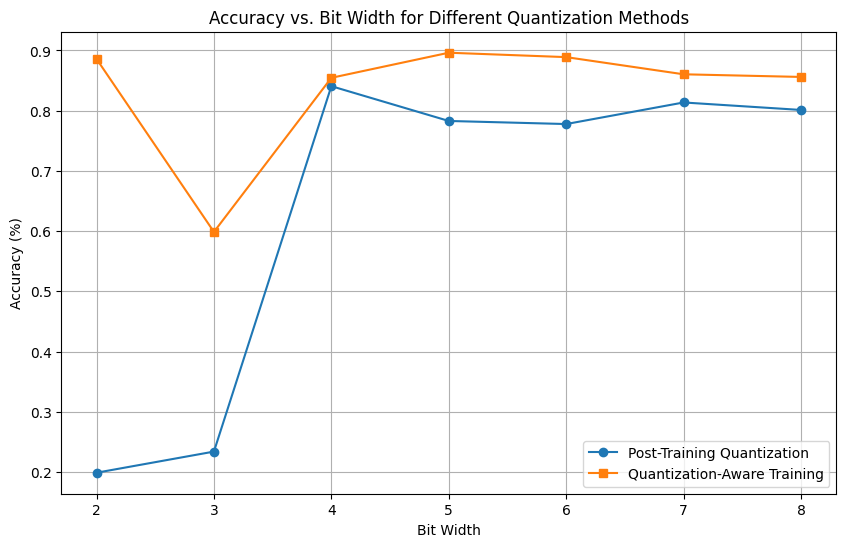

In [47]:
plot_accuracy_comparison(bit_widths, accuracies_post, accuracies_qat)

In [54]:
def print_summary_table(bit_widths, post_quant_accuracies, qat_accuracies):
    """Print a summary table of accuracies and differences."""
    print("\nSummary of Accuracy vs. Bit Width:")
    print("-" * 75)  # Increased width

    # Headers with increased column widths
    print(f"{'Bit Width':^12} {'Post-Training Quant.':^22} {'QAT':^22} {'Difference':^15}")
    print("-" * 75)  # Increased width

    # Data rows with center alignment
    for i, bits in enumerate(bit_widths):
        diff = qat_accuracies[i] - post_quant_accuracies[i]
        print(f"{bits:^12} {post_quant_accuracies[i]:^22.2f} {qat_accuracies[i]:^22.2f} {diff:^15.2f}")
    print("-" * 75)  # Bottom border

In [55]:
print_summary_table(bit_widths, accuracies_post, accuracies_qat)


Summary of Accuracy vs. Bit Width:
---------------------------------------------------------------------------
 Bit Width    Post-Training Quant.           QAT             Difference   
---------------------------------------------------------------------------
     2                0.20                   0.89               0.69      
     3                0.23                   0.60               0.36      
     4                0.84                   0.85               0.01      
     5                0.78                   0.90               0.11      
     6                0.78                   0.89               0.11      
     7                0.81                   0.86               0.05      
     8                0.80                   0.86               0.05      
---------------------------------------------------------------------------
